# IQ sampling — simulações do roteiro do vídeo

Este caderno reproduz, numericamente, **todas as cenas** da animação
[`iq_sampling.py`](iq_sampling.py) (cena `IQSampling`) e do texto
[`docs/.../IQ sampling.md`](../../../docs/Detecção%20de%20amplitude%20e%20fase%20em%20RF/IQ%20sampling/IQ%20sampling.md).

Cada seção corresponde a uma cena do vídeo, na mesma ordem. A ideia é poder
mexer nos parâmetros e ver o efeito — algo que o vídeo, sendo fixo, não permite.

**Convenção usada em todo o material** (a mesma de Schilcher):

$$y(t) = A\sin(\omega t + \varphi_0) = I\sin(\omega t) + Q\cos(\omega t),
\qquad I = A\cos\varphi_0, \qquad Q = A\sin\varphi_0$$

Cada amostra é a **projeção vertical** do fasor de ângulo $\omega t + \varphi_0$.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Paleta equivalente à da animação, para as figuras combinarem com o vídeo
COR_RF, COR_I, COR_Q = "#58a6ff", "#d4a72c", "#3fb950"
COR_ERRO, COR_ERRO2, COR_DIGITAL = "#f85149", "#ff8c42", "#2dd4bf"

plt.rcParams.update({
    "figure.figsize": (11, 4),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

# Parâmetros do exemplo (os mesmos do vídeo)
A, FI0 = 1.0, np.deg2rad(35)
I0, Q0 = A * np.cos(FI0), A * np.sin(FI0)
print(f"A = {A},  phi0 = {np.rad2deg(FI0):.0f}°   ->   I = {I0:.4f},  Q = {Q0:.4f}")

A = 1.0,  phi0 = 35°   ->   I = 0.8192,  Q = 0.5736


## Cena 1 — Representação polar × cartesiana

As duas formas descrevem o mesmo sinal. A identidade da soma de arcos leva uma na outra:

$$A\sin(\omega t + \varphi_0) = \underbrace{A\cos\varphi_0}_{I}\sin\omega t + \underbrace{A\sin\varphi_0}_{Q}\cos\omega t$$

A volta é Pitágoras mais arco-tangente. A célula abaixo confirma que as duas
expressões coincidem ponto a ponto.

erro máximo entre as duas formas: 7.754213937616328e-16
A recuperado = 1.000000   phi0 recuperado = 35.0000°


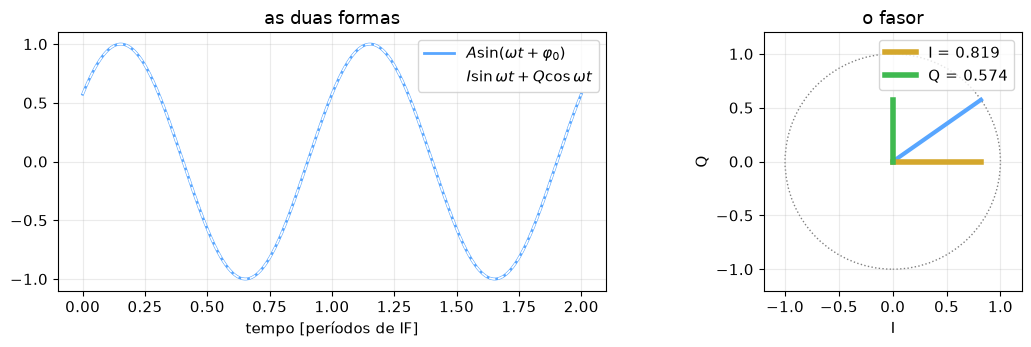

In [4]:
t = np.linspace(0, 2, 1000)          # em períodos da IF
w = 2 * np.pi                        # omega*t = 2*pi*(t em períodos)

polar     = A * np.sin(w * t + FI0)
cartesian = I0 * np.sin(w * t) + Q0 * np.cos(w * t)

print("erro máximo entre as duas formas:", np.max(np.abs(polar - cartesian)))

# e a volta: de (I, Q) para (A, phi0)
A_rec   = np.hypot(I0, Q0)
fi_rec  = np.arctan2(Q0, I0)
print(f"A recuperado = {A_rec:.6f}   phi0 recuperado = {np.rad2deg(fi_rec):.4f}°")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(t, polar, color=COR_RF, lw=2, label=r"$A\sin(\omega t+\varphi_0)$")
ax[0].plot(t, cartesian, "--", color="w", lw=1.2, label=r"$I\sin\omega t + Q\cos\omega t$")
ax[0].set_xlabel("tempo [períodos de IF]"); ax[0].legend(); ax[0].set_title("as duas formas")

ax[1].plot([0, I0], [0, Q0], color=COR_RF, lw=3)
ax[1].plot([0, I0], [0, 0], color=COR_I, lw=4, label=f"I = {I0:.3f}")
ax[1].plot([0, 0], [0, Q0], color=COR_Q, lw=4, label=f"Q = {Q0:.3f}")
ax[1].add_patch(plt.Circle((0, 0), A, fill=False, ls=":", color="grey"))
ax[1].set_xlim(-1.2, 1.2); ax[1].set_ylim(-1.2, 1.2); ax[1].set_aspect("equal")
ax[1].set_xlabel("I"); ax[1].set_ylabel("Q"); ax[1].legend(); ax[1].set_title("o fasor")
plt.tight_layout(); plt.show()

## Cena 2 — O que o ADC consegue medir

O ADC entrega **um escalar por amostra**: a projeção vertical do fasor.
Uma amostra isolada não define o vetor — qualquer fasor cuja ponta esteja na
reta horizontal $y = \text{amostra}$ produz exatamente a mesma leitura.

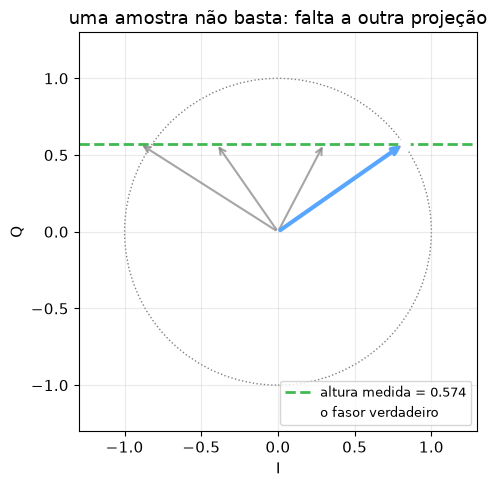

In [5]:
y0 = A * np.sin(FI0)       # a primeira amostra, em omega*t = 0  ->  vale Q

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.add_patch(plt.Circle((0, 0), A, fill=False, ls=":", color="grey"))
ax.axhline(y0, color=COR_Q, ls="--", lw=2, label=f"altura medida = {y0:.3f}")

# todos estes fasores dariam a MESMA amostra
for x in (-0.9, -0.4, 0.3, 0.82):
    ax.annotate("", xy=(x, y0), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="grey", lw=1.5, alpha=0.7))
ax.annotate("", xy=(I0, Q0), xytext=(0, 0),
            arrowprops=dict(arrowstyle="->", color=COR_RF, lw=3))
ax.plot(I0, Q0, "o", color="w", ms=8, label="o fasor verdadeiro")

ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal")
ax.set_xlabel("I"); ax.set_ylabel("Q"); ax.legend(loc="lower right", fontsize=9)
ax.set_title("uma amostra não basta: falta a outra projeção")
plt.tight_layout(); plt.show()

## Cena 3 — Amostragem síncrona $f_s = 4\,f_{IF}$

Com quatro amostras por período, o avanço de fase entre amostras é

$$\Delta\phi = \omega T_s = 2\pi f_{IF}\cdot\frac{1}{4f_{IF}} = \frac{\pi}{2} = 90^\circ$$

Nos quatro instantes, uma das funções-base vale zero e a outra vale um — é daí
que sai a separação de $I$ e $Q$, sem filtro nenhum.

   k   omega*t      y[k]      esperado
  0      0°   +0.5736      Q = +0.5736
  1     90°   +0.8192      I = +0.8192
  2    180°   -0.5736     -Q = -0.5736
  3    270°   -0.8192     -I = -0.8192
  4    360°   +0.5736      Q = +0.5736
  5    450°   +0.8192      I = +0.8192
  6    540°   -0.5736     -Q = -0.5736
  7    630°   -0.8192     -I = -0.8192


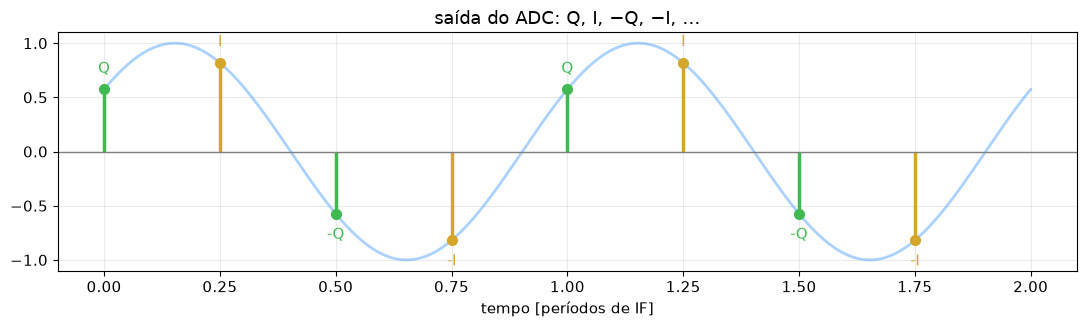

In [6]:
def amostrar(A=A, fi0=FI0, n=8, m=4):
    '''n amostras com fs = m*f_IF; devolve os índices e os valores y[k].'''
    k = np.arange(n)
    return k, A * np.sin(2 * np.pi * k / m + fi0)

k, y = amostrar()
I_ref, Q_ref = A * np.cos(FI0), A * np.sin(FI0)

print("   k   omega*t      y[k]      esperado")
nomes = ["Q", "I", "-Q", "-I"]
esperado = [Q_ref, I_ref, -Q_ref, -I_ref]
for i in range(8):
    print(f"  {i}   {90*i:4d}°   {y[i]:+.4f}    {nomes[i%4]:>3} = {esperado[i%4]:+.4f}")

t = np.linspace(0, 2, 800)
plt.figure(figsize=(11, 3.4))
plt.plot(t, A*np.sin(2*np.pi*t + FI0), color=COR_RF, alpha=0.5, lw=2)
for i in range(8):
    cor = COR_Q if i % 2 == 0 else COR_I
    plt.vlines(i/4, 0, y[i], color=cor, lw=2.5)
    plt.plot(i/4, y[i], "o", color=cor, ms=7)
    plt.annotate(nomes[i % 4], (i/4, y[i]), textcoords="offset points",
                 xytext=(0, 12 if y[i] >= 0 else -18), ha="center", color=cor)
plt.axhline(0, color="grey", lw=1)
plt.xlabel("tempo [períodos de IF]"); plt.title("saída do ADC: Q, I, −Q, −I, …")
plt.tight_layout(); plt.show()

## Cena 4 — Os quatro vetores $(y_{i+1},\, y_i)$

O algoritmo agrupa duas amostras consecutivas num ponto do plano: a abscissa é a
amostra **nova**, a ordenada é a **anterior**. Os quatro pares ficam a exatamente
90° um do outro.

A armadilha: as letras dentro do vetor **não** são o nome do eixo onde a ponta
está — são os comprimentos medidos em $t_0$, já girados. Girar 90° no sentido
anti-horário leva $(x, y) \to (-y,\, x)$, portanto $(I,Q) \to (-Q,\,I)$.
Escrever $(-I,\,Q)$ seria um **espelhamento**, não uma rotação.

  i    par (y_{i+1}, y_i)        ângulo      esperado
  0   (+0.819, +0.574)       35.00°      35.00°
  1   (-0.574, +0.819)      125.00°     125.00°
  2   (-0.819, -0.574)      215.00°     215.00°
  3   (+0.574, -0.819)      305.00°     305.00°

(I,Q) girado 90° = [-0.5736  0.8192]  | par em t1 = [-0.5736  0.8192]
já (-I, Q) seria   = [-0.8192  0.5736]  <- diferente!


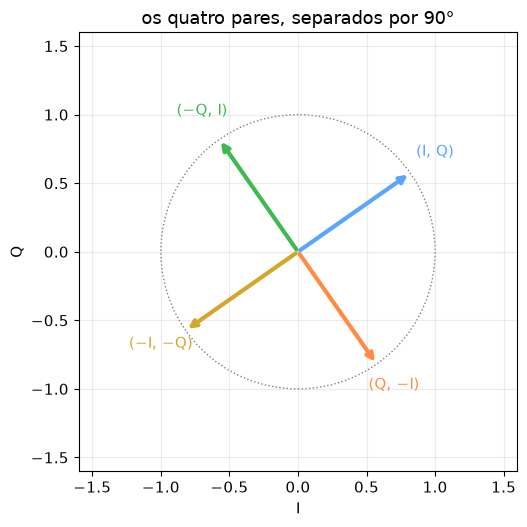

In [7]:
pares = np.array([[y[i+1], y[i]] for i in range(4)])   # (y_{i+1}, y_i)
rot = lambda v, g: np.array([[np.cos(g), -np.sin(g)], [np.sin(g), np.cos(g)]]) @ v

print("  i    par (y_{i+1}, y_i)        ângulo      esperado")
for i, v in enumerate(pares):
    ang = np.rad2deg(np.arctan2(v[1], v[0])) % 360
    print(f"  {i}   ({v[0]:+.3f}, {v[1]:+.3f})      {ang:6.2f}°     {np.rad2deg(FI0)+90*i:6.2f}°")

# a verificação da regra de rotação
print("\n(I,Q) girado 90° =", np.round(rot(pares[0], np.pi/2), 4),
      " | par em t1 =", np.round(pares[1], 4))
print("já (-I, Q) seria   =", np.round(np.array([-I0, Q0]), 4), " <- diferente!")

fig, ax = plt.subplots(figsize=(5.4, 5.4))
ax.add_patch(plt.Circle((0, 0), A, fill=False, ls=":", color="grey"))
cores = [COR_RF, COR_Q, COR_I, COR_ERRO2]
rotulos = ["(I, Q)", "(−Q, I)", "(−I, −Q)", "(Q, −I)"]
for v, c, r in zip(pares, cores, rotulos):
    ax.annotate("", xy=tuple(v), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=c, lw=3))
    ax.annotate(r, xy=tuple(v * 1.22), color=c, ha="center", fontsize=11)
ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6); ax.set_aspect("equal")
ax.set_xlabel("I"); ax.set_ylabel("Q")
ax.set_title("os quatro pares, separados por 90°")
plt.tight_layout(); plt.show()

## Cena 5 — O algoritmo de rotação

Como o par gira $+90°$ por amostra, basta desgirar:

$$\begin{pmatrix} I \\ Q \end{pmatrix}_{t_i} =
\begin{pmatrix} \cos\Delta\phi_i & -\sin\Delta\phi_i \\
\sin\Delta\phi_i & \cos\Delta\phi_i \end{pmatrix}
\begin{pmatrix} y_{i+1} \\ y_i \end{pmatrix},
\qquad \Delta\phi_i = -i\cdot 90°$$

Todos os coeficientes são **0, +1 e −1**: nenhum multiplicador, nenhuma tabela
trigonométrica. Qualquer par consecutivo devolve o mesmo $(I, Q)$.

In [8]:
def iq_sampling(y, m=4):
    '''Estima (I, Q) para cada par consecutivo, desfazendo i*(2pi/m).'''
    saida = []
    for i in range(len(y) - 1):
        dphi = -i * 2 * np.pi / m
        R = np.array([[np.cos(dphi), -np.sin(dphi)],
                      [np.sin(dphi),  np.cos(dphi)]])
        saida.append(R @ np.array([y[i+1], y[i]]))
    return np.array(saida)

est = iq_sampling(y)
print("  i        I          Q        A        phi0")
for i, (Ie, Qe) in enumerate(est):
    print(f"  {i}   {Ie:+.4f}   {Qe:+.4f}   {np.hypot(Ie,Qe):.4f}   "
          f"{np.rad2deg(np.arctan2(Qe,Ie)):7.3f}°")

print("\nas matrizes, para i = 0, 1, 2, 3:")
for i in range(4):
    d = -i * np.pi / 2
    print(f"  dphi = {np.rad2deg(d):5.0f}° ->",
          np.round(np.array([[np.cos(d), -np.sin(d)], [np.sin(d), np.cos(d)]]), 0).tolist())

  i        I          Q        A        phi0
  0   +0.8192   +0.5736   1.0000    35.000°
  1   +0.8192   +0.5736   1.0000    35.000°
  2   +0.8192   +0.5736   1.0000    35.000°
  3   +0.8192   +0.5736   1.0000    35.000°
  4   +0.8192   +0.5736   1.0000    35.000°
  5   +0.8192   +0.5736   1.0000    35.000°
  6   +0.8192   +0.5736   1.0000    35.000°

as matrizes, para i = 0, 1, 2, 3:
  dphi =     0° -> [[1.0, -0.0], [0.0, 1.0]]
  dphi =   -90° -> [[0.0, 1.0], [-1.0, 0.0]]
  dphi =  -180° -> [[-1.0, 0.0], [-0.0, -1.0]]
  dphi =  -270° -> [[-0.0, -1.0], [1.0, -0.0]]


## Cena 6 — Primeiro uso: detectar um erro de fase

Numa malha de LLRF a fase deve ficar parada. Partindo de $I = Q = 1$
($\varphi_0 = 45°$, $A = \sqrt2$), uma perturbação que leve a fase a 35° é lida
diretamente por $\operatorname{atan}(Q/I)$.

Repare que a **amplitude não muda**: o ponto desliza *sobre* o círculo — é a
assinatura de uma perturbação puramente de fase.

referência (45°):  amostras = [ 1.  1. -1. -1.]
    I = 1.000   Q = 1.000   A = 1.414   phi = 45.00°

perturbado (35°):  amostras = [ 0.811  1.158 -0.811 -1.158]
    I = 1.158   Q = 0.811   A = 1.414   phi = 35.00°

erro visto pela malha: 45.0° − 35.0° = 10.0°


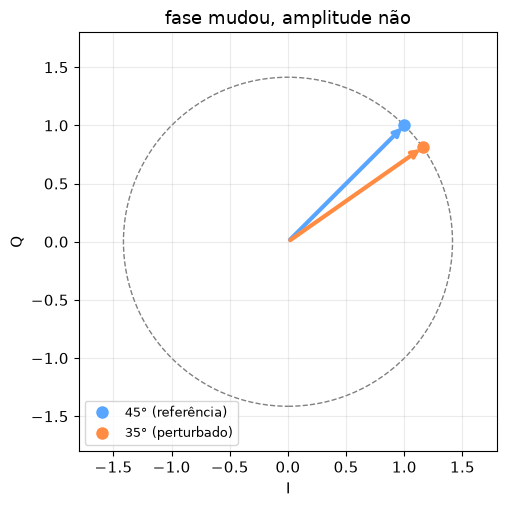

In [9]:
A2 = np.sqrt(2.0)

def medir(fi_graus, n=9, m=4, A=A2):
    k, yy = amostrar(A=A, fi0=np.deg2rad(fi_graus), n=n, m=m)
    est = iq_sampling(yy, m=m)
    return yy, est

y_ref, est_ref = medir(45)
y_per, est_per = medir(35)

for nome, yy, est in [("referência (45°)", y_ref, est_ref),
                      ("perturbado (35°)", y_per, est_per)]:
    Ie, Qe = est[0]
    print(f"{nome}:  amostras = {np.round(yy[:4], 3)}")
    print(f"    I = {Ie:.3f}   Q = {Qe:.3f}   "
          f"A = {np.hypot(Ie,Qe):.3f}   phi = {np.rad2deg(np.arctan2(Qe,Ie)):.2f}°\n")

fase_ref = np.rad2deg(np.arctan2(*est_ref[0][::-1]))
fase_per = np.rad2deg(np.arctan2(*est_per[0][::-1]))
print(f"erro visto pela malha: {fase_ref:.1f}° − {fase_per:.1f}° = "
      f"{fase_ref - fase_per:.1f}°")

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.add_patch(plt.Circle((0, 0), A2, fill=False, ls="--", color="grey"))
for est, cor, lbl in [(est_ref, COR_RF, "45° (referência)"),
                      (est_per, COR_ERRO2, "35° (perturbado)")]:
    ax.annotate("", xy=tuple(est[0]), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=cor, lw=3))
    ax.plot(*est[0], "o", color=cor, ms=8, label=lbl)
ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.8, 1.8); ax.set_aspect("equal")
ax.set_xlabel("I"); ax.set_ylabel("Q"); ax.legend(loc="lower left", fontsize=9)
ax.set_title("fase mudou, amplitude não")
plt.tight_layout(); plt.show()

### O limite da hipótese de estabilidade

O algorimo supõe que amplitude e fase **não mudam entre duas amostras**. No
instante do salto, o par que atravessa a descontinuidade mistura os dois estados
e produz uma leitura intermediária, que não corresponde a nenhum dos dois.

  par 0 (y1, y0):  fase =   45.00°
  par 1 (y2, y1):  fase =   45.00°
  par 2 (y3, y2):  fase =   45.00°
  par 3 (y4, y3):  fase =   39.05°  <- par que atravessa o salto
  par 4 (y5, y4):  fase =   35.00°
  par 5 (y6, y5):  fase =   35.00°
  par 6 (y7, y6):  fase =   35.00°
  par 7 (y8, y7):  fase =   35.00°
  par 8 (y9, y8):  fase =   35.00°
  par 9 (y10, y9):  fase =   35.00°
  par 10 (y11, y10):  fase =   35.00°


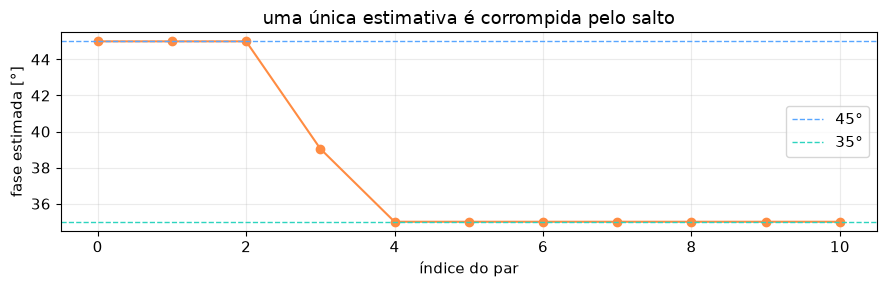

In [10]:
# sinal que salta de 45° para 35° na amostra n = 4
n = 12
k = np.arange(n)
fi = np.where(k < 4, np.deg2rad(45), np.deg2rad(35))
y_salto = A2 * np.sin(2 * np.pi * k / 4 + fi)
est_salto = iq_sampling(y_salto)
fases = np.rad2deg(np.arctan2(est_salto[:, 1], est_salto[:, 0]))

for i, f in enumerate(fases):
    marca = "  <- par que atravessa o salto" if i == 3 else ""
    print(f"  par {i} (y{i+1}, y{i}):  fase = {f:7.2f}°{marca}")

plt.figure(figsize=(9, 3))
plt.plot(fases, "o-", color=COR_ERRO2)
plt.axhline(45, color=COR_RF, ls="--", lw=1, label="45°")
plt.axhline(35, color=COR_DIGITAL, ls="--", lw=1, label="35°")
plt.xlabel("índice do par"); plt.ylabel("fase estimada [°]"); plt.legend()
plt.title("uma única estimativa é corrompida pelo salto")
plt.tight_layout(); plt.show()

## Cena 7 — Segundo uso: ler uma mensagem na fase

Quando a fase carrega informação, o processo é **idêntico**; muda só o destino
do número. Num QPSK, quatro ângulos codificam dois bits cada.

  I = +1.000  Q = +1.000  ->    45.0°  ->  00
  I = -1.000  Q = -1.000  ->   225.0°  ->  11
  I = +1.000  Q = -1.000  ->   315.0°  ->  10
  I = -1.000  Q = +1.000  ->   135.0°  ->  01

mensagem transmitida: 00 11 10 01
mensagem recebida:    00 11 10 01


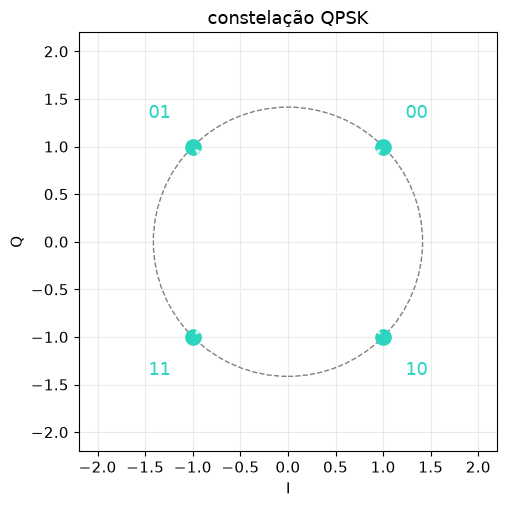

In [11]:
CONSTELACAO = {45: "00", 135: "01", 225: "11", 315: "10"}
M_SIMB = 16          # amostras por símbolo: a fase tem de ficar parada dentro dele

mensagem = [45, 225, 315, 135]           # "00 11 10 01"
recebido, fases_lidas = [], []

for ang in mensagem:
    _, yy = amostrar(A=A2, fi0=np.deg2rad(ang), n=M_SIMB)
    est = iq_sampling(yy)
    Ie, Qe = est.mean(axis=0)            # média sobre o símbolo: ganha SNR
    f = np.rad2deg(np.arctan2(Qe, Ie)) % 360
    # decide pelo ponto mais próximo da constelação
    simbolo = min(CONSTELACAO, key=lambda c: abs((f - c + 180) % 360 - 180))
    fases_lidas.append(f); recebido.append(CONSTELACAO[simbolo])
    print(f"  I = {Ie:+.3f}  Q = {Qe:+.3f}  ->  {f:6.1f}°  ->  {CONSTELACAO[simbolo]}")

print("\nmensagem transmitida:", " ".join(CONSTELACAO[a] for a in mensagem))
print("mensagem recebida:   ", " ".join(recebido))

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.add_patch(plt.Circle((0, 0), A2, fill=False, ls="--", color="grey"))
for ang, bits in CONSTELACAO.items():
    a = np.deg2rad(ang)
    ax.plot(A2*np.cos(a), A2*np.sin(a), "o", ms=11, color=COR_DIGITAL)
    ax.annotate(bits, (1.35*A2*np.cos(a), 1.35*A2*np.sin(a)),
                ha="center", va="center", fontsize=13, color=COR_DIGITAL)
for f in fases_lidas:
    a = np.deg2rad(f)
    ax.annotate("", xy=(A2*np.cos(a), A2*np.sin(a)), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="w", lw=1.5, alpha=0.6))
ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2); ax.set_aspect("equal")
ax.set_xlabel("I"); ax.set_ylabel("Q"); ax.set_title("constelação QPSK")
plt.tight_layout(); plt.show()

## Cena 8 — Generalização $f_s = m\,f_{IF}$

Com outro inteiro $m$, o passo é $\Delta\phi = 2\pi/m$ e o sistema 2×2 continua
solúvel — mas aparece $1/\sin\Delta\phi$ multiplicando tudo. Quando $\Delta\phi$
se afasta de 90°, o ruído é amplificado.

In [12]:
def estimar_generico(y, m, i=0):
    """Resolve o sistema 2x2 para um passo angular qualquer dphi = 2*pi/m."""
    dphi = 2 * np.pi / m
    R = np.array([[np.cos(i*dphi), -np.cos((i+1)*dphi)],
                  [-np.sin(i*dphi),  np.sin((i+1)*dphi)]]) / np.sin(dphi)
    return R @ np.array([y[i+1], y[i]])


# O fator 1/|sin(dphi)| é a amplificação de PIOR CASO. O erro de fase para um
# phi0 fixo também depende da orientação da elipse de erro, então só a média
# sobre phi0 reproduz a tendência limpa.
rng = np.random.default_rng(0)
print("  m     dphi    1/|sin dphi|   RMS |erro (I,Q)|   RMS erro de fase")
for m in (3, 4, 5, 6, 8, 12, 20, 40):
    dphi = 2 * np.pi / m
    e_vec, e_fase = [], []
    for fi in np.linspace(0, 2*np.pi, 60, endpoint=False):
        Ir, Qr = np.cos(fi), np.sin(fi)
        for _ in range(60):
            _, yy = amostrar(fi0=fi, n=3, m=m)
            yy = yy + rng.normal(0, 0.01, yy.shape)       # ruído de 1 %
            Ie, Qe = estimar_generico(yy, m)
            e_vec.append(np.hypot(Ie - Ir, Qe - Qr))
            e_fase.append(np.rad2deg(np.angle(
                np.exp(1j * (np.arctan2(Qe, Ie) - fi)))))
    print(f" {m:3d}   {np.rad2deg(dphi):6.1f}°   {1/abs(np.sin(dphi)):9.2f}"
          f"   {np.sqrt(np.mean(np.square(e_vec))):13.4f}"
          f"   {np.std(e_fase):15.3f}°")

print("\nm = 4 (dphi = 90°) é o mínimo, e m = 3 e m = 6 empatam: "
      "ambos têm |sin dphi| = 0,866")

  m     dphi    1/|sin dphi|   RMS |erro (I,Q)|   RMS erro de fase
   3    120.0°        1.15          0.0163             0.661°


   4     90.0°        1.00          0.0139             0.561°
   5     72.0°        1.05          0.0148             0.606°
   6     60.0°        1.15          0.0166             0.667°
   8     45.0°        1.41          0.0199             0.804°
  12     30.0°        2.00          0.0279             1.141°
  20     18.0°        3.24          0.0454             1.848°
  40      9.0°        6.39          0.0894             3.638°

m = 4 (dphi = 90°) é o mínimo, e m = 3 e m = 6 empatam: ambos têm |sin dphi| = 0,866


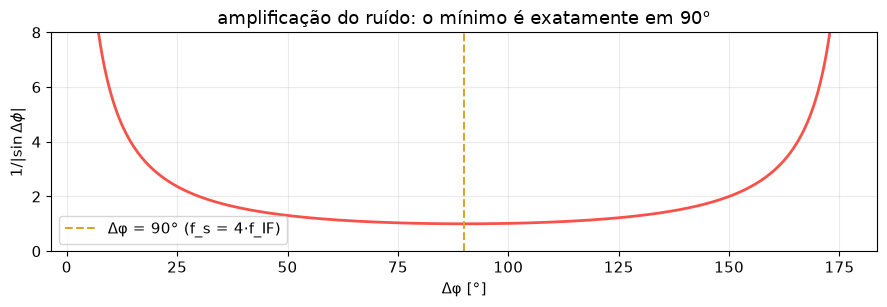

In [13]:
graus = np.linspace(5, 175, 400)
plt.figure(figsize=(9, 3.2))
plt.plot(graus, 1/np.abs(np.sin(np.deg2rad(graus))), color=COR_ERRO, lw=2)
plt.axvline(90, color=COR_I, ls="--", label="Δφ = 90° (f_s = 4·f_IF)")
plt.ylim(0, 8); plt.xlabel("Δφ [°]"); plt.ylabel(r"$1/|\sin\Delta\phi|$")
plt.legend(); plt.title("amplificação do ruído: o mínimo é exatamente em 90°")
plt.tight_layout(); plt.show()

## Cena 9 — Offset DC: ondulação em $f_{IF}$

Um offset $c$ soma-se a **todas** as amostras. Depois da rotação, o erro troca
de sinal a cada passo: o ponto $(I,Q)$ salta num quadrado e aparece uma
ondulação com período de 4 amostras — ou seja, exatamente em $f_s/4 = f_{IF}$.

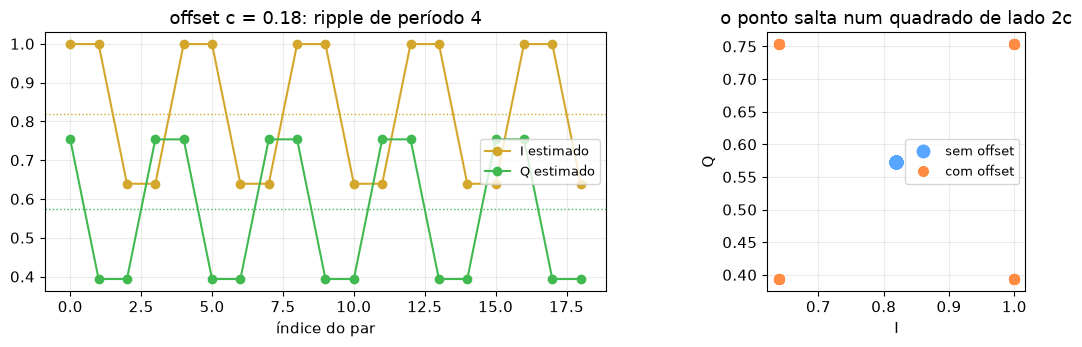

espalhamento das estimativas com offset:
   I varia de 0.639 a 0.999
   Q varia de 0.394 a 0.754
   lado do quadrado = 0.36  (esperado: 2c = 0.36 )


In [14]:
c = 0.18
k, y_lim = amostrar(n=20)
est_ok  = iq_sampling(y_lim)
est_off = iq_sampling(y_lim + c)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(est_off[:, 0], "o-", color=COR_I, label="I estimado")
ax[0].plot(est_off[:, 1], "o-", color=COR_Q, label="Q estimado")
ax[0].axhline(I0, color=COR_I, ls=":", lw=1); ax[0].axhline(Q0, color=COR_Q, ls=":", lw=1)
ax[0].set_xlabel("índice do par"); ax[0].legend(fontsize=9)
ax[0].set_title(f"offset c = {c}: ripple de período 4")

ax[1].plot(est_ok[:, 0], est_ok[:, 1], "o", color=COR_RF, ms=9, label="sem offset")
ax[1].plot(est_off[:, 0], est_off[:, 1], "o", color=COR_ERRO2, ms=7, label="com offset")
ax[1].set_aspect("equal"); ax[1].set_xlabel("I"); ax[1].set_ylabel("Q")
ax[1].legend(fontsize=9); ax[1].set_title("o ponto salta num quadrado de lado 2c")
plt.tight_layout(); plt.show()

print("espalhamento das estimativas com offset:")
print("   I varia de", round(est_off[:,0].min(), 3), "a", round(est_off[:,0].max(), 3))
print("   Q varia de", round(est_off[:,1].min(), 3), "a", round(est_off[:,1].max(), 3))
print("   lado do quadrado =", round(est_off[:,0].max() - est_off[:,0].min(), 3),
      " (esperado: 2c =", 2*c, ")")

## Cena 10 — A regra da dobra (aliasing)

Depois de amostrar, o eixo de frequências se **dobra como uma sanfona** a cada
$f_s/2$. Frequências diferentes chegam ao mesmo ponto e tornam-se
indistinguíveis.

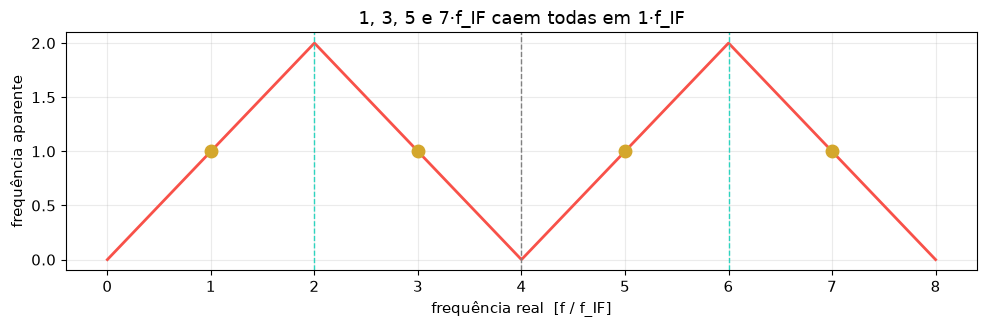

 f real    f aparente
  0·f_IF     0.00·f_IF
  1·f_IF     1.00·f_IF
  2·f_IF     2.00·f_IF
  3·f_IF     1.00·f_IF
  4·f_IF     0.00·f_IF
  5·f_IF     1.00·f_IF
  6·f_IF     2.00·f_IF
  7·f_IF     1.00·f_IF
  8·f_IF     0.00·f_IF


In [15]:
def alias(f, fs):
    '''Frequência aparente de f depois da amostragem a fs.'''
    f = np.asarray(f) % fs
    return np.where(f > fs/2, fs - f, f)

fs = 4.0                      # em unidades de f_IF
f_real = np.linspace(0, 8, 2000)

plt.figure(figsize=(10, 3.4))
plt.plot(f_real, alias(f_real, fs), color=COR_ERRO, lw=2)
for v in (2, 6):
    plt.axvline(v, color=COR_DIGITAL, ls="--", lw=1)
plt.axvline(4, color="grey", ls="--", lw=1)
for v in (1, 3, 5, 7):
    plt.plot(v, alias(v, fs), "o", color=COR_I, ms=9)
plt.xlabel("frequência real  [f / f_IF]")
plt.ylabel("frequência aparente")
plt.title("1, 3, 5 e 7·f_IF caem todas em 1·f_IF")
plt.tight_layout(); plt.show()

print(" f real    f aparente")
for v in range(0, 9):
    print(f"  {v}·f_IF     {alias(v, fs):.2f}·f_IF")

## Cena 11 — Harmônicas ímpares sobre a portadora

Não linearidades geram harmônicas de $f_{IF}$. Com $f_s = 4f_{IF}$,
**todas as ímpares** caem sobre o sinal, porque $k$ ímpar implica
$k \equiv \pm 1 \pmod 4$.

In [16]:
print("  k   k·f_IF   k mod 4   aparece em   veredito")
for k_h in range(1, 9):
    ap = float(alias(k_h, fs))
    if k_h == 1:                     v = "o próprio sinal"
    elif abs(ap - 1) < 1e-9:         v = "<<< SOBRE f_IF"
    elif abs(ap - 2) < 1e-9:         v = "em cima de Nyquist"
    else:                            v = "vira DC"
    print(f"  {k_h}    {k_h}·f_IF      {k_h % 4}        {ap:.2f}·f_IF     {v}")

  k   k·f_IF   k mod 4   aparece em   veredito
  1    1·f_IF      1        1.00·f_IF     o próprio sinal
  2    2·f_IF      2        2.00·f_IF     em cima de Nyquist
  3    3·f_IF      3        1.00·f_IF     <<< SOBRE f_IF
  4    4·f_IF      0        0.00·f_IF     vira DC
  5    5·f_IF      1        1.00·f_IF     <<< SOBRE f_IF
  6    6·f_IF      2        2.00·f_IF     em cima de Nyquist
  7    7·f_IF      3        1.00·f_IF     <<< SOBRE f_IF
  8    8·f_IF      0        0.00·f_IF     vira DC


  n    3ª harmônica    −fundamental    diferença
  0     +0.000000      -0.000000     0.0e+00
  1     -1.000000      -1.000000     0.0e+00
  2     +0.000000      -0.000000     4.9e-16
  3     +1.000000      +1.000000     0.0e+00
  4     -0.000000      +0.000000     9.8e-16
  5     -1.000000      -1.000000     0.0e+00
  6     +0.000000      -0.000000     1.5e-15
  7     +1.000000      +1.000000     0.0e+00
  8     -0.000000      +0.000000     2.0e-15


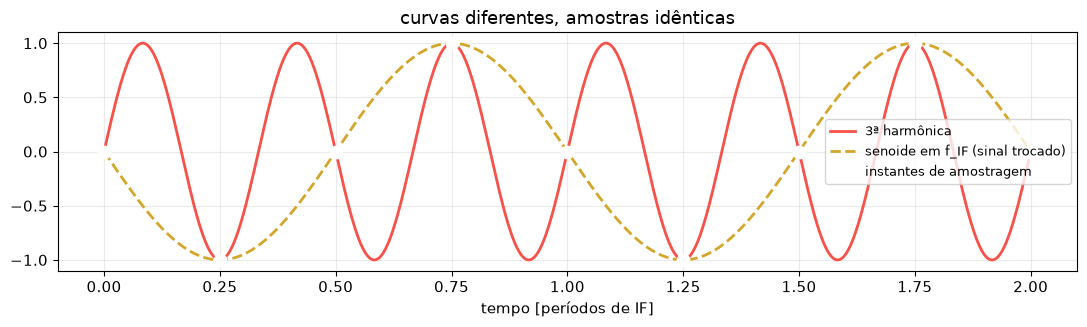

In [17]:
# A prova no tempo: a 3ª harmônica dá as MESMAS amostras da fundamental
t = np.linspace(0, 2, 1000)
h3 = np.sin(3 * 2*np.pi * t)
h1 = -np.sin(2*np.pi * t)
k = np.arange(9) / 4

print("  n    3ª harmônica    −fundamental    diferença")
for i, ki in enumerate(k):
    a, b = np.sin(3*2*np.pi*ki), -np.sin(2*np.pi*ki)
    print(f"  {i}     {a:+.6f}      {b:+.6f}     {abs(a-b):.1e}")

plt.figure(figsize=(11, 3.4))
plt.plot(t, h3, color=COR_ERRO, lw=2, label="3ª harmônica")
plt.plot(t, h1, "--", color=COR_I, lw=2, label="senoide em f_IF (sinal trocado)")
plt.plot(k, np.sin(3*2*np.pi*k), "o", color="w", ms=9, label="instantes de amostragem")
plt.xlabel("tempo [períodos de IF]"); plt.legend(fontsize=9)
plt.title("curvas diferentes, amostras idênticas")
plt.tight_layout(); plt.show()

### O estrago no fasor medido

A harmônica aliasada vira um fasor em $f_{IF}$ que se **soma vetorialmente** ao
sinal. O erro de fase resultante é da ordem de $A_3/A_1$ radianos.

In [18]:
print("  A3/A1      dBc     erro de fase (pior caso)")
for rel in (0.1, 0.03, 0.01, 0.003, 0.001):
    print(f"  {rel:6.3f}   {20*np.log10(rel):6.1f}      "
          f"{np.rad2deg(np.arcsin(rel)):6.3f}°")

# verificação por soma vetorial, varrendo a fase da harmônica
A1, A3 = 1.0, 0.01
fases_h = np.linspace(0, 2*np.pi, 721)
erro = [np.rad2deg(np.angle((A1 + A3*np.exp(1j*ph)))) for ph in fases_h]
print(f"\nerro máximo medido por soma vetorial: {max(np.abs(erro)):.4f}°")
print(f"previsto por arcsin(A3/A1):           {np.rad2deg(np.arcsin(A3/A1)):.4f}°")

  A3/A1      dBc     erro de fase (pior caso)
   0.100    -20.0       5.739°
   0.030    -30.5       1.719°
   0.010    -40.0       0.573°
   0.003    -50.5       0.172°
   0.001    -60.0       0.057°

erro máximo medido por soma vetorial: 0.5730°
previsto por arcsin(A3/A1):           0.5730°


## Resumo

**Vantagens** — um único ADC (sem desbalanço I/Q), $(I,Q)$ a partir de apenas
2 amostras, matrizes com 0 e ±1 (nenhum multiplicador) e latência mínima.

**Limitações** — exige $f_s = 4f_{IF}$ exato; offset DC e erro de fase viram
ripple em $f_{IF}$; **todas as harmônicas ímpares caem sobre a portadora**; e
$\Delta\phi$ longe de 90° amplifica ruído.

**Saídas** — Non-IQ sampling ($f_s/f_{IF} = N/M$) e Digital Down Conversion.

A célula abaixo mostra por que o Non-IQ resolve o problema das harmônicas:
basta escolher $N/M$ em que a 3ª não colida com a fundamental. A condição de
colisão é $k\,M \bmod N \in \{M,\; N-M\}$.

In [19]:
def colide(k, N, M):
    r = (k * M) % N
    return r in (M % N, (N - M) % N)

for N, M in [(4, 1), (5, 2), (9, 2), (7, 2), (16, 3)]:
    maus = [k for k in range(2, 12) if colide(k, N, M)]
    print(f"  fs/fIF = {N}/{M} = {N/M:5.2f}   harmônicas que caem sobre f_IF: {maus}")

  fs/fIF = 4/1 =  4.00   harmônicas que caem sobre f_IF: [3, 5, 7, 9, 11]
  fs/fIF = 5/2 =  2.50   harmônicas que caem sobre f_IF: [4, 6, 9, 11]
  fs/fIF = 9/2 =  4.50   harmônicas que caem sobre f_IF: [8, 10]
  fs/fIF = 7/2 =  3.50   harmônicas que caem sobre f_IF: [6, 8]
  fs/fIF = 16/3 =  5.33   harmônicas que caem sobre f_IF: []
